# COU 07506 Digital Signal Processing
## Week 4 — z-Transform Laboratory: Poles, Zeros and Stability

| | |
|---|---|
| **Name** | MAIMUNA SHABANI HAJI |
| **Registration number** | 250242423358 |
| **Date** | 25 November 2026 |
| **Group** | 30 |
| **Lecturer** | Dr. Haji Fimbombaya |

**Group 30 members**

1. PAUL MASHAKA NYANDA
2. MAIMUNA SHABANI HAJI
3. ABDULKARIM MAKIWA SAID
4. SYLIVESTER M. MAGUHWA
5. ABRON JAMES MPIRA

## Pre-lab preparation
Handout §2.2–2.4 read. ✔

**(a) Poles of $H(z) = 1/(1 - 0.9z^{-1} + 0.81z^{-2})$. Is it stable?**
Multiply by $z^2$: $z^2 - 0.9z + 0.81 = 0$, so
$z = \dfrac{0.9 \pm \sqrt{0.81 - 3.24}}{2} = 0.45 \pm j0.779$.
$|p| = \sqrt{0.45^2 + 0.779^2} = \sqrt{0.81} = 0.9$, at angle $\pm 60°$ ($\pm\pi/3$), so $p = 0.9e^{\pm j\pi/3}$.
Both poles are inside the unit circle ($0.9 < 1$), so the causal system is **stable**.

**(b) Partial-fraction expansion of $X(z) = 1/[(1 - 0.5z^{-1})(1 - 0.25z^{-1})]$.**
$X(z) = \dfrac{A}{1 - 0.5z^{-1}} + \dfrac{B}{1 - 0.25z^{-1}}$, with
$A = \dfrac{1}{1 - 0.25/0.5} = 2$ and $B = \dfrac{1}{1 - 0.5/0.25} = -1$.

$X(z) = \dfrac{2}{1 - 0.5z^{-1}} - \dfrac{1}{1 - 0.25z^{-1}}$, so for the causal ROC $|z| > 0.5$:
$x(n) = [2(0.5)^n - (0.25)^n]\,u(n)$.

## Standard imports

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import signal
from scipy.io import wavfile
from IPython.display import Audio, display
plt.rcParams["figure.figsize"] = (9, 3.5)

In [2]:
# Check of pre-lab (a)
p = np.roots([1, -0.9, 0.81])
print("poles:", np.round(p, 4), " |p| =", np.round(np.abs(p), 4),
      " angle =", np.round(np.degrees(np.angle(p)), 1), "deg")

poles: [0.45+0.7794j 0.45-0.7794j]  |p| = [0.9 0.9]  angle = [ 60. -60.] deg


## Task 4.1 — A pole-zero plotting function

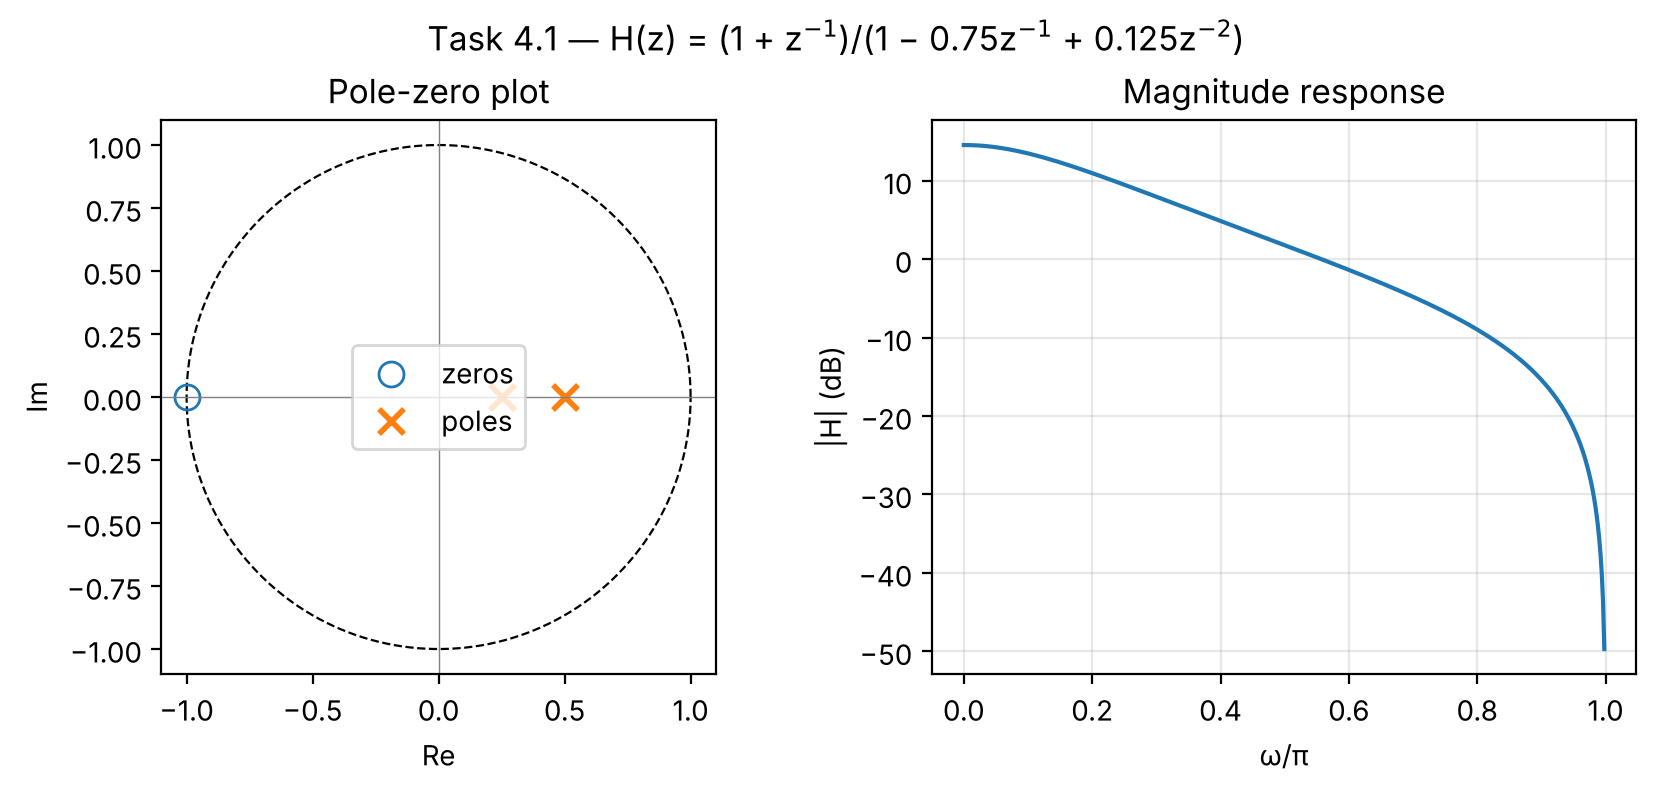

zeros: [-1.]  poles: [0.5  0.25]  stable: True


In [3]:
def zplane(b, a, ax=None):
    z, p, k = signal.tf2zpk(b, a)
    ax = ax or plt.gca()
    th = np.linspace(0, 2*np.pi, 400)
    ax.plot(np.cos(th), np.sin(th), "k--", lw=0.8)
    ax.plot(z.real, z.imag, "o", mfc="none", ms=9, label="zeros")
    ax.plot(p.real, p.imag, "x", ms=9, mew=2, label="poles")
    ax.axhline(0, color="grey", lw=0.5); ax.axvline(0, color="grey", lw=0.5)
    ax.set_aspect("equal"); ax.legend(); ax.set_xlabel("Re"); ax.set_ylabel("Im")
    return z, p

b, a = [1, 1], [1, -0.75, 0.125]
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10, 3.6))
z, p = zplane(b, a, ax1)
ax1.set_title("Pole-zero plot")
w, H = signal.freqz(b, a, worN=512)
ax2.plot(w/np.pi, 20*np.log10(np.abs(H) + 1e-12)); ax2.set_xlabel("ω/π"); ax2.set_ylabel("|H| (dB)")
ax2.set_title("Magnitude response"); ax2.grid(alpha=0.3)
fig.suptitle("Task 4.1 — H(z) = (1 + z$^{-1}$)/(1 − 0.75z$^{-1}$ + 0.125z$^{-2}$)", y=1.02)
plt.show()
print("zeros:", z, " poles:", p, " stable:", np.all(np.abs(p) < 1))

The poles at 0.5 and 0.25 lie on the positive real axis, close to $z = 1$ ($\omega = 0$), so the gain is highest
at DC: $20\log_{10}(5.33) = 14.5$ dB. The zero at $z = -1$ ($\omega = \pi$) forces the response to $-\infty$ dB at
half the sampling rate. This is a **low-pass** system, and it is **stable** because both poles are inside the
unit circle.

## Task 4.2 — Inverse z-transform with `residuez`

In [4]:
r, p, k = signal.residuez([1], [1, -0.75, 0.125])
print("residues", r, "poles", p)
n = np.arange(10)
x_pf = sum(ri * pi**n for ri, pi in zip(r, p)).real
impulse = np.zeros(10); impulse[0] = 1
x_lf = signal.lfilter([1], [1, -0.75, 0.125], impulse)
print(np.allclose(x_pf, x_lf))
print("pre-lab (b): A = 2 at pole 0.5, B = -1 at pole 0.25  ->  matches residuez")

residues [-1.  2.] poles [0.25 0.5 ]
True
pre-lab (b): A = 2 at pole 0.5, B = -1 at pole 0.25  ->  matches residuez


residues [-5.  6.] poles [0.25 0.5 ] direct term k = []
partial fractions == lfilter: True
== closed form 6(0.5)^n - 5(0.25)^n: True


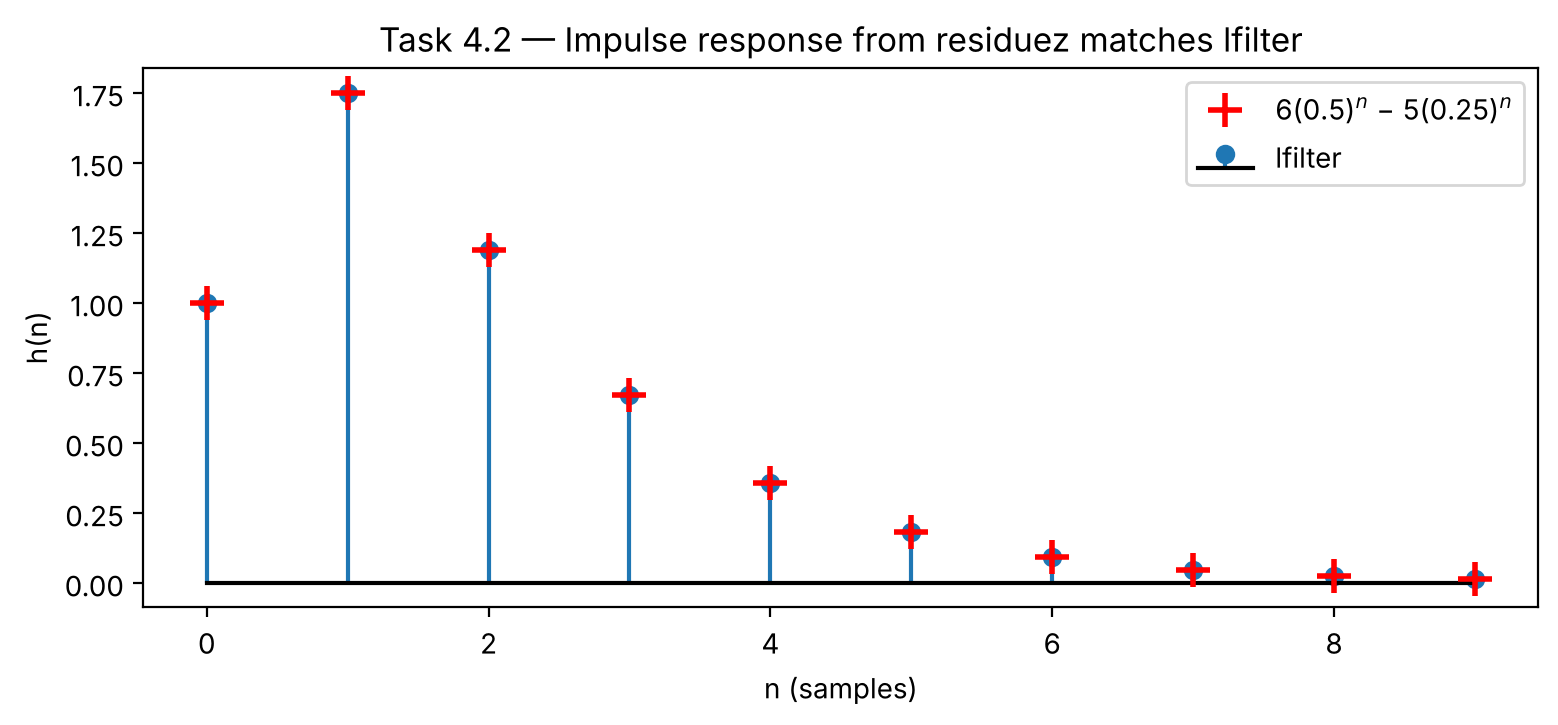

In [5]:
# Same for the system of Task 4.1 (b = [1, 1])
r, p, k = signal.residuez([1, 1], [1, -0.75, 0.125])
print("residues", np.round(r.real, 6), "poles", p, "direct term k =", k)
h_pf = sum(ri * pi**n for ri, pi in zip(r, p)).real
h_lf = signal.lfilter([1, 1], [1, -0.75, 0.125], impulse)
h_cf = 6*0.5**n - 5*0.25**n
print("partial fractions == lfilter:", np.allclose(h_pf, h_lf))
print("== closed form 6(0.5)^n - 5(0.25)^n:", np.allclose(h_pf, h_cf))
plt.stem(n, h_lf, basefmt="k-", label="lfilter")
plt.plot(n, h_cf, "r+", ms=12, mew=2, label="6(0.5)$^n$ − 5(0.25)$^n$")
plt.xlabel("n (samples)"); plt.ylabel("h(n)"); plt.legend()
plt.title("Task 4.2 — Impulse response from residuez matches lfilter"); plt.show()

The residues for $b = [1]$ are 2 (pole 0.5) and −1 (pole 0.25), exactly my pre-lab answer (b). For $b = [1, 1]$
the residues are 6 and −5, which confirms $h(n) = 6(0.5)^n - 5(0.25)^n$ (handout Example 2.5).

## Task 4.3 — Pole position and the impulse response
Pole pair $p = re^{\pm j\pi/4}$, so $A(z) = 1 - 2r\cos(\pi/4)z^{-1} + r^2z^{-2}$ and $B(z) = 1$.

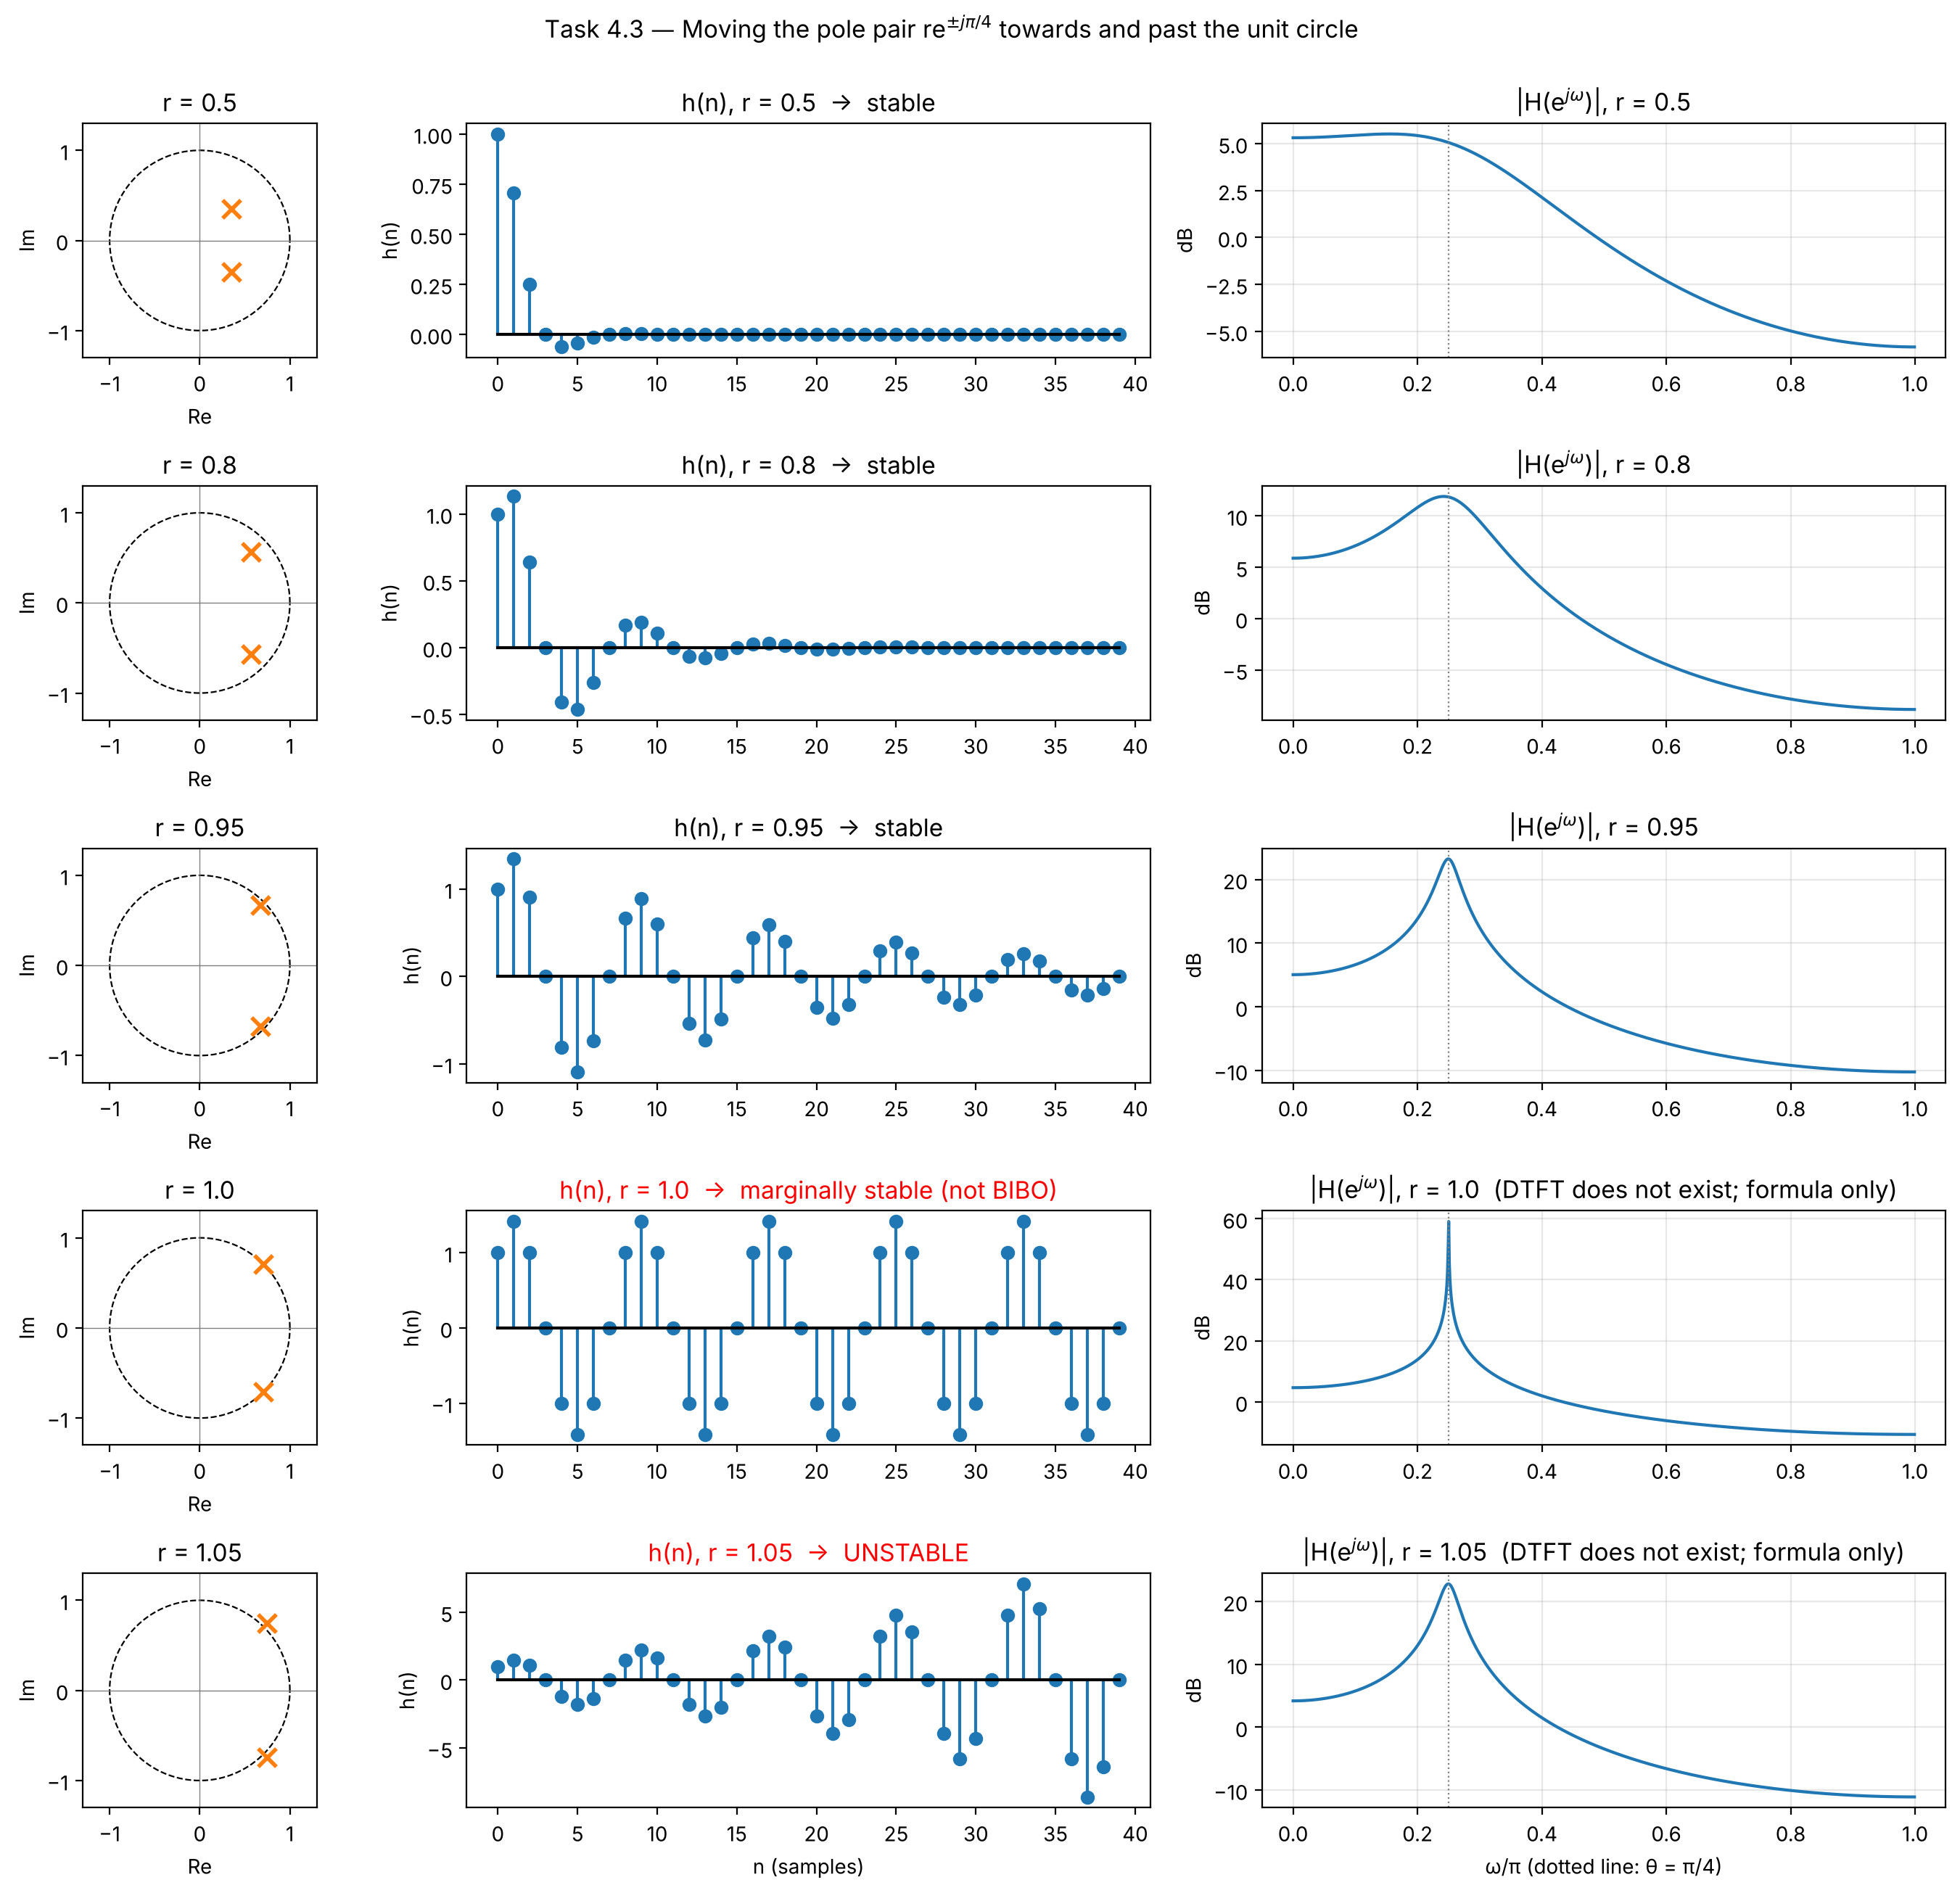

In [6]:
radii = [0.5, 0.8, 0.95, 1.0, 1.05]
n = np.arange(40)
imp = np.zeros(40); imp[0] = 1
fig, axes = plt.subplots(len(radii), 3, figsize=(14, 13),
                         gridspec_kw={"width_ratios": [1, 2.2, 2.2]})
for row, r in zip(axes, radii):
    a = [1, -2*r*np.cos(np.pi/4), r**2]
    h = signal.lfilter([1], a, imp)
    w, H = signal.freqz([1], a, worN=999)        # grid avoids hitting w = pi/4 exactly
    zplane([1], a, row[0]); row[0].legend().remove()
    row[0].set_xlim(-1.3, 1.3); row[0].set_ylim(-1.3, 1.3)
    row[0].set_title(f"r = {r}")
    stable = r < 1
    row[1].stem(n, h, basefmt="k-")
    row[1].set_title(f"h(n), r = {r}  ->  " + ("stable" if stable else
                     "marginally stable (not BIBO)" if r == 1 else "UNSTABLE"),
                     color="k" if stable else "r")
    row[1].set_ylabel("h(n)")
    row[2].plot(w/np.pi, 20*np.log10(np.abs(H)))
    row[2].axvline(0.25, color="grey", ls=":", lw=0.8)
    row[2].set_title(f"|H(e$^{{jω}}$)|, r = {r}" + ("" if stable else "  (DTFT does not exist; formula only)"))
    row[2].set_ylabel("dB"); row[2].grid(alpha=0.3)
axes[-1][1].set_xlabel("n (samples)"); axes[-1][2].set_xlabel("ω/π (dotted line: θ = π/4)")
fig.suptitle("Task 4.3 — Moving the pole pair re$^{±jπ/4}$ towards and past the unit circle", y=1.0)
plt.tight_layout(); plt.show()

**Observations**
- **Decay:** $h(n)$ behaves like $r^n\cos(n\pi/4 + \phi)$, so the envelope decays as $r^n$. For r = 0.5 it is gone
  in about 5 samples. For r = 0.8 it lasts about 20 samples, and for r = 0.95 it rings for the whole 40 samples.
- **Oscillation:** in every case the oscillation period is 8 samples, because the pole angle $\theta = \pi/4$
  sets the frequency, not $r$.
- **Peak sharpness:** the peak of $|H|$ is at $\omega \approx \pi/4$. As $r \to 1$ it becomes taller and narrower
  (r = 0.5 is a broad bump, r = 0.95 is a sharp 25 dB resonance). At r = 1 the gain becomes infinite at exactly
  $\pi/4$.
- **Unstable values:** r = 1.0 is marginally stable. $h(n)$ is a sinusoid that never decays, so it is not
  absolutely summable and the system is not BIBO-stable. **r = 1.05 is unstable:** $h(n)$ grows as $1.05^n$.
  For r ≥ 1 the unit circle is outside the ROC of the causal system, so the plotted $|H|$ is only the formula
  evaluated on the circle, not a real frequency response.

## Task 4.4 — Stability of given systems

system                               poles                             max|p|  verdict
H1 = 1/(1 − 1.6z⁻¹ + 0.89z⁻²)        0.8+0.5j, 0.8-0.5j                 0.943  STABLE
                                     |h(39)| = 0.0672
H2 = (1 + z⁻¹)/(1 − 2.5z⁻¹ + z⁻²)    2, 0.5                             2.000  UNSTABLE
                                     |h(39)| = 1.1e+12
H3 = 1/(1 + 0.5z⁻¹ − 0.5z⁻²)         -1, 0.5                            1.000  MARGINAL (pole on |z|=1) -> not BIBO stable
                                     |h(39)| = 0.667
H4 = 1 − z⁻⁴                         (only at z = 0)                    0.000  STABLE
                                     |h(39)| = 0


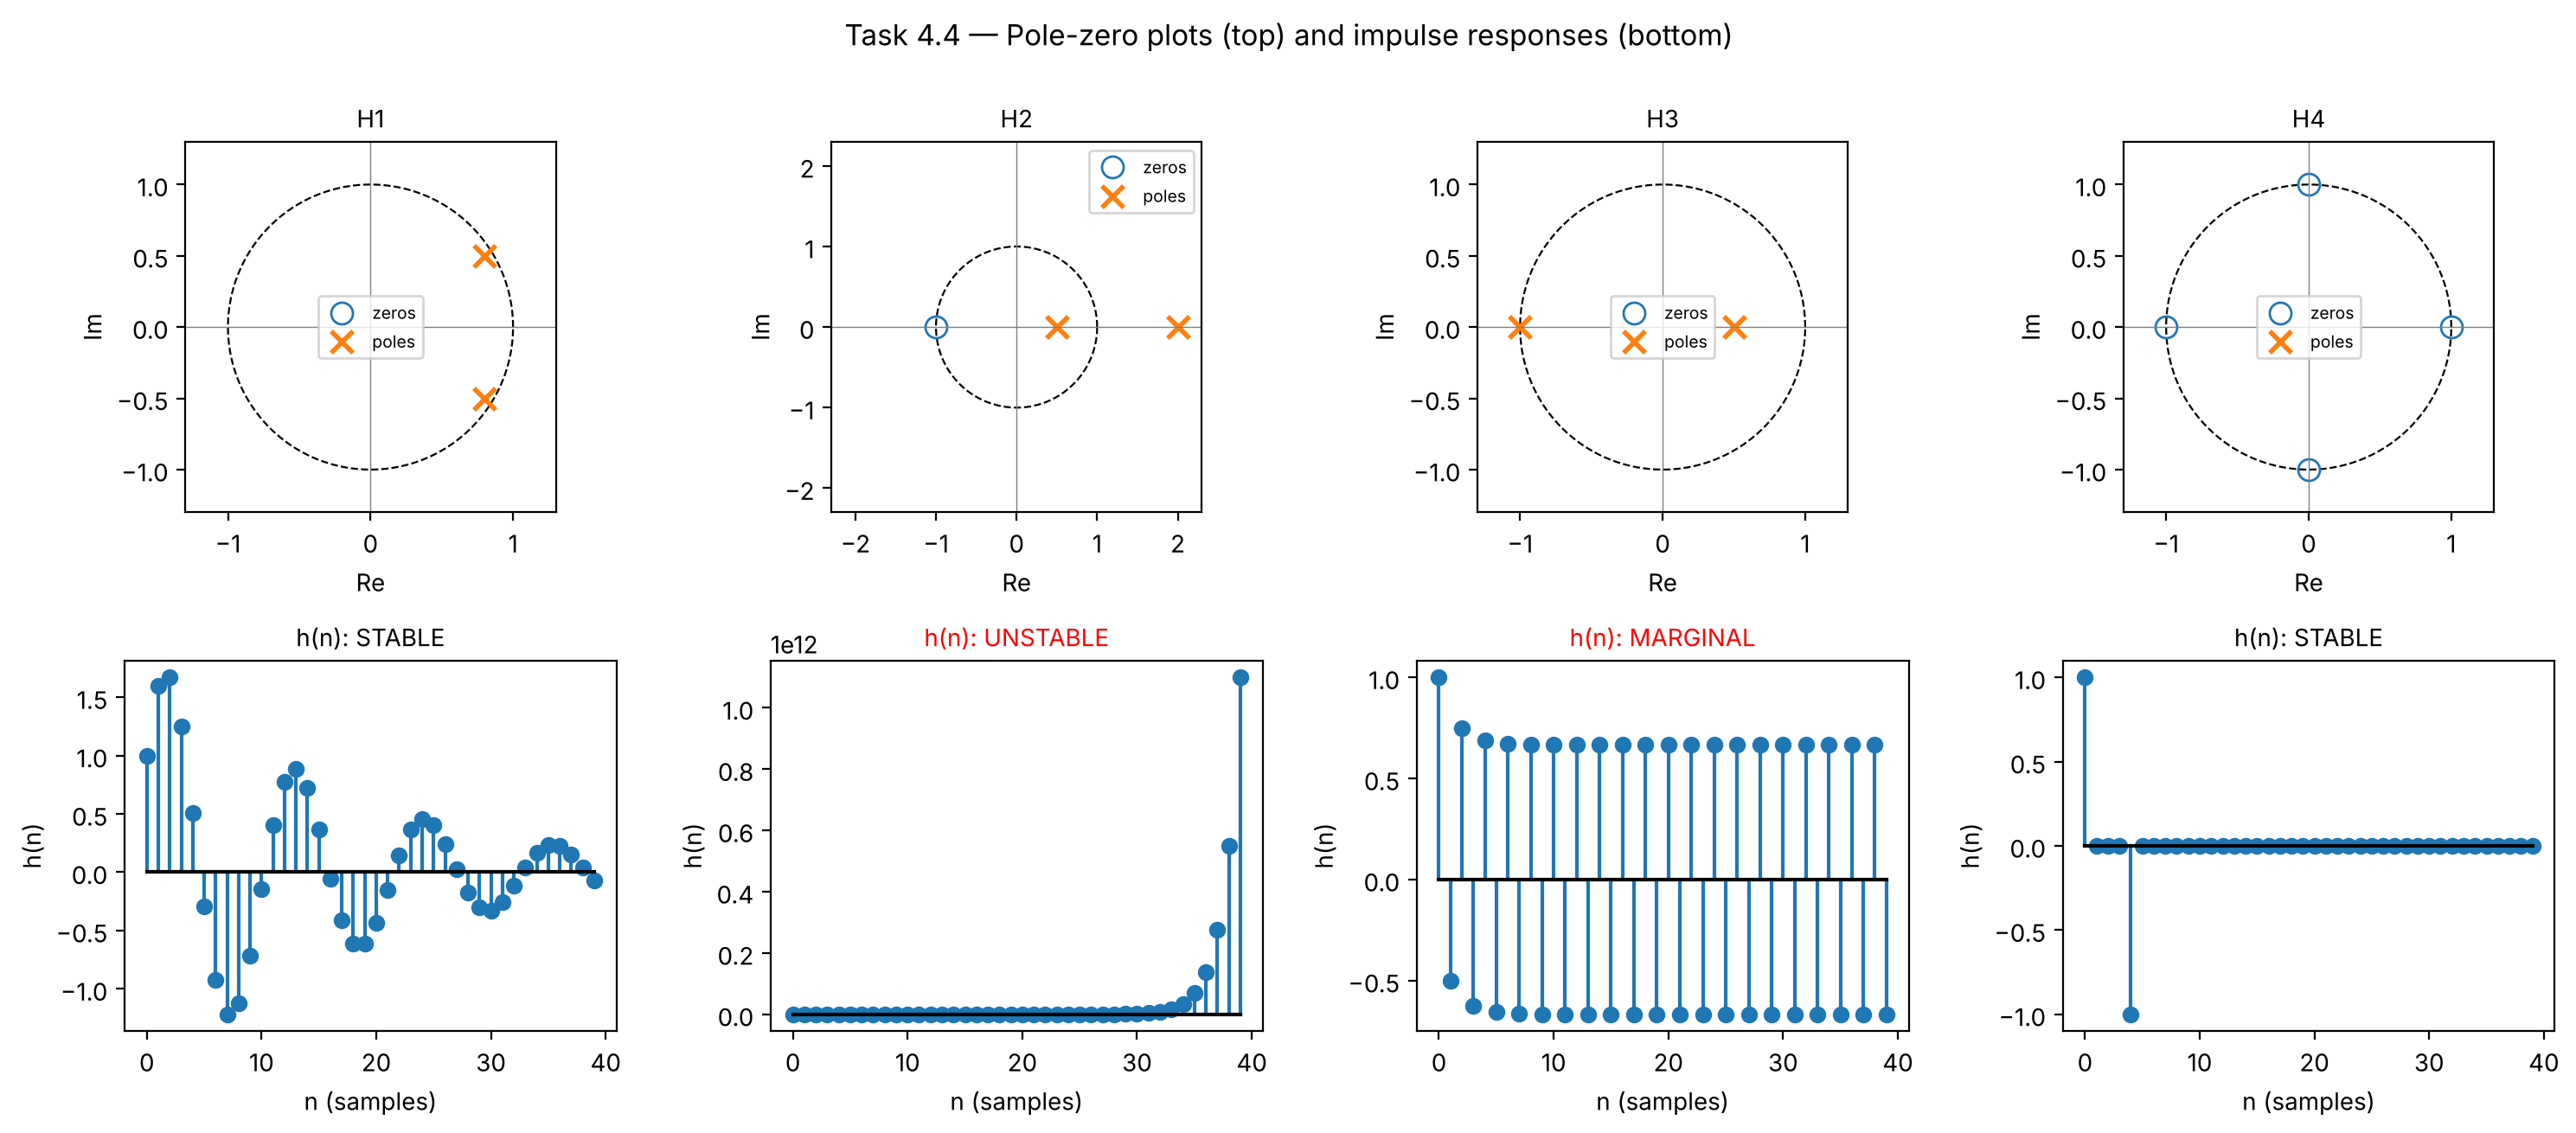

In [7]:
systems = {
    "H1 = 1/(1 − 1.6z⁻¹ + 0.89z⁻²)":      ([1],             [1, -1.6, 0.89]),
    "H2 = (1 + z⁻¹)/(1 − 2.5z⁻¹ + z⁻²)":  ([1, 1],          [1, -2.5, 1]),
    "H3 = 1/(1 + 0.5z⁻¹ − 0.5z⁻²)":       ([1],             [1, 0.5, -0.5]),
    "H4 = 1 − z⁻⁴":                       ([1, 0, 0, 0, -1], [1]),
}
n = np.arange(40)
imp = np.zeros(40); imp[0] = 1
fig, axes = plt.subplots(2, 4, figsize=(15, 6.5))
print(f"{'system':36s} {'poles':32s} {'max|p|':>7}  verdict")
for i, (name, (b, a)) in enumerate(systems.items()):
    z, p = zplane(b, a, axes[0, i])
    axes[0, i].set_title(name.split(" =")[0], fontsize=10)
    axes[0, i].legend(fontsize=7)
    lim = max(1.3, 1.15*np.max(np.abs(np.concatenate([z, p, [0]]))))
    axes[0, i].set_xlim(-lim, lim); axes[0, i].set_ylim(-lim, lim)
    h = signal.lfilter(b, a, imp)
    axes[1, i].stem(n, h, basefmt="k-")
    axes[1, i].set_xlabel("n (samples)"); axes[1, i].set_ylabel("h(n)")
    pmax = np.max(np.abs(p)) if len(p) else 0.0
    if pmax < 1 - 1e-9:
        verdict = "STABLE"
    elif pmax <= 1 + 1e-9:
        verdict = "MARGINAL (pole on |z|=1) -> not BIBO stable"
    else:
        verdict = "UNSTABLE"
    axes[1, i].set_title(f"h(n): {verdict.split(' ')[0]}", fontsize=10,
                         color="k" if verdict == "STABLE" else "r")
    ptxt = ", ".join(f"{pp:.3g}" for pp in p) if len(p) else "(only at z = 0)"
    print(f"{name:36s} {ptxt:32s} {pmax:7.3f}  {verdict}")
    print(f"{'':36s} |h(39)| = {abs(h[-1]):.3g}")
fig.suptitle("Task 4.4 — Pole-zero plots (top) and impulse responses (bottom)", y=1.0)
plt.tight_layout(); plt.show()

**Classification**

| System | Poles | Verdict | Evidence in h(n) |
|---|---|---|---|
| $H_1$ | $0.8 \pm j0.5$, $\lvert p\rvert = 0.943$ | **stable** | decaying oscillation |
| $H_2$ | 2 and 0.5 | **unstable** (pole at 2 is outside) | grows like $2^n$ |
| $H_3$ | 0.5 and −1 | **marginally stable, not BIBO-stable** (pole on the unit circle at $z=-1$) | settles to a ±0.67 alternation that never decays |
| $H_4$ | four poles at $z = 0$ (FIR) | **stable** (every FIR filter is) | just $\{1, 0, 0, 0, -1\}$, then zero (SciPy does not draw poles at the origin, so none appear in its plot) |

**Checkpoint 4:** the stability classification (above) and the resonator response (Task 4.5) are shown.

## Task 4.5 — Design a resonator
Peak at $f_0$ = 1 kHz with $f_s$ = 8 kHz, so $\theta = 2\pi f_0/f_s = \pi/4$. With r = 0.97, the poles are at $0.97e^{\pm j\pi/4}$:
$A(z) = 1 - 2(0.97)\cos(\pi/4)z^{-1} + 0.97^2z^{-2}$.
Zeros at $z = \pm1$ give $B(z) = (1 - z^{-1})(1 + z^{-1}) = 1 - z^{-2}$.

theta = 0.7853981633974483 rad = pi/4: True
b = [ 1  0 -1]   a = [ 1.     -1.3718  0.9409]


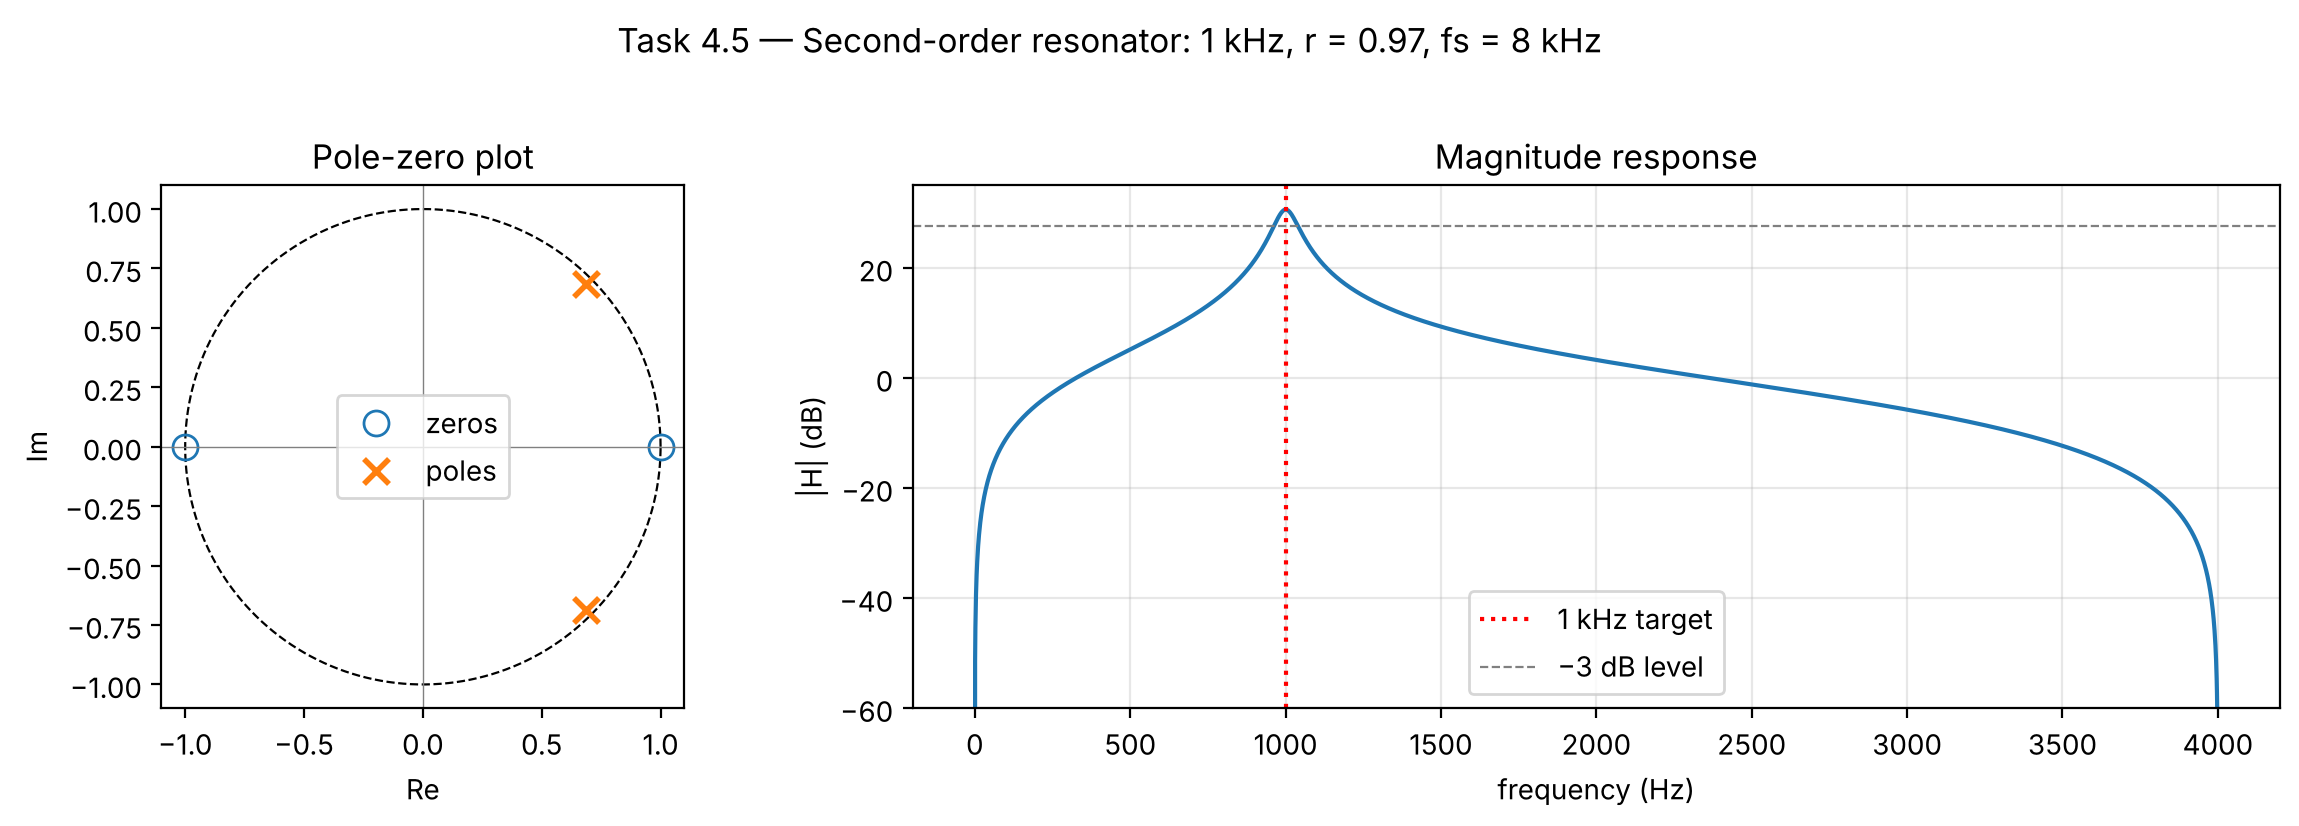

peak at 1001.0 Hz, peak gain = 30.6 dB
-3 dB bandwidth = 76 Hz (estimate 2(1-r)·fs/2π = 76 Hz)
|H| at 0 Hz = 0.0e+00,  at fs/2 = 4.63e-04  (blocked by the zeros)


In [8]:
fs, f0, r = 8000, 1000, 0.97
theta = 2*np.pi*f0/fs
b = np.array([1, 0, -1])                                  # zeros at z = +1 and z = -1
a = np.array([1, -2*r*np.cos(theta), r**2])               # poles at r e^{±j theta}
print("theta =", theta, "rad = pi/4:", np.isclose(theta, np.pi/4))
print("b =", b, "  a =", np.round(a, 4))

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4), gridspec_kw={"width_ratios": [1, 2]})
zplane(b, a, ax1); ax1.set_title("Pole-zero plot")
f, H = signal.freqz(b, a, worN=4096, fs=fs)
HdB = 20*np.log10(np.abs(H) + 1e-12)
ax2.plot(f, HdB); ax2.set_ylim(-60, 35)
ax2.axvline(f0, color="r", ls=":", label="1 kHz target")
ipk = np.argmax(np.abs(H))
above = f[HdB >= HdB[ipk] - 3]
ax2.axhline(HdB[ipk] - 3, color="grey", ls="--", lw=0.8, label="−3 dB level")
ax2.set_xlabel("frequency (Hz)"); ax2.set_ylabel("|H| (dB)"); ax2.legend(); ax2.grid(alpha=0.3)
ax2.set_title("Magnitude response")
fig.suptitle("Task 4.5 — Second-order resonator: 1 kHz, r = 0.97, fs = 8 kHz", y=1.02)
plt.tight_layout(); plt.show()
print(f"peak at {f[ipk]:.1f} Hz, peak gain = {HdB[ipk]:.1f} dB")
print(f"-3 dB bandwidth = {above[-1]-above[0]:.0f} Hz "
      f"(estimate 2(1-r)·fs/2π = {2*(1-r)*fs/(2*np.pi):.0f} Hz)")
print(f"|H| at 0 Hz = {abs(H[0]):.1e},  at fs/2 = {abs(H[-1]):.2e}  (blocked by the zeros)")

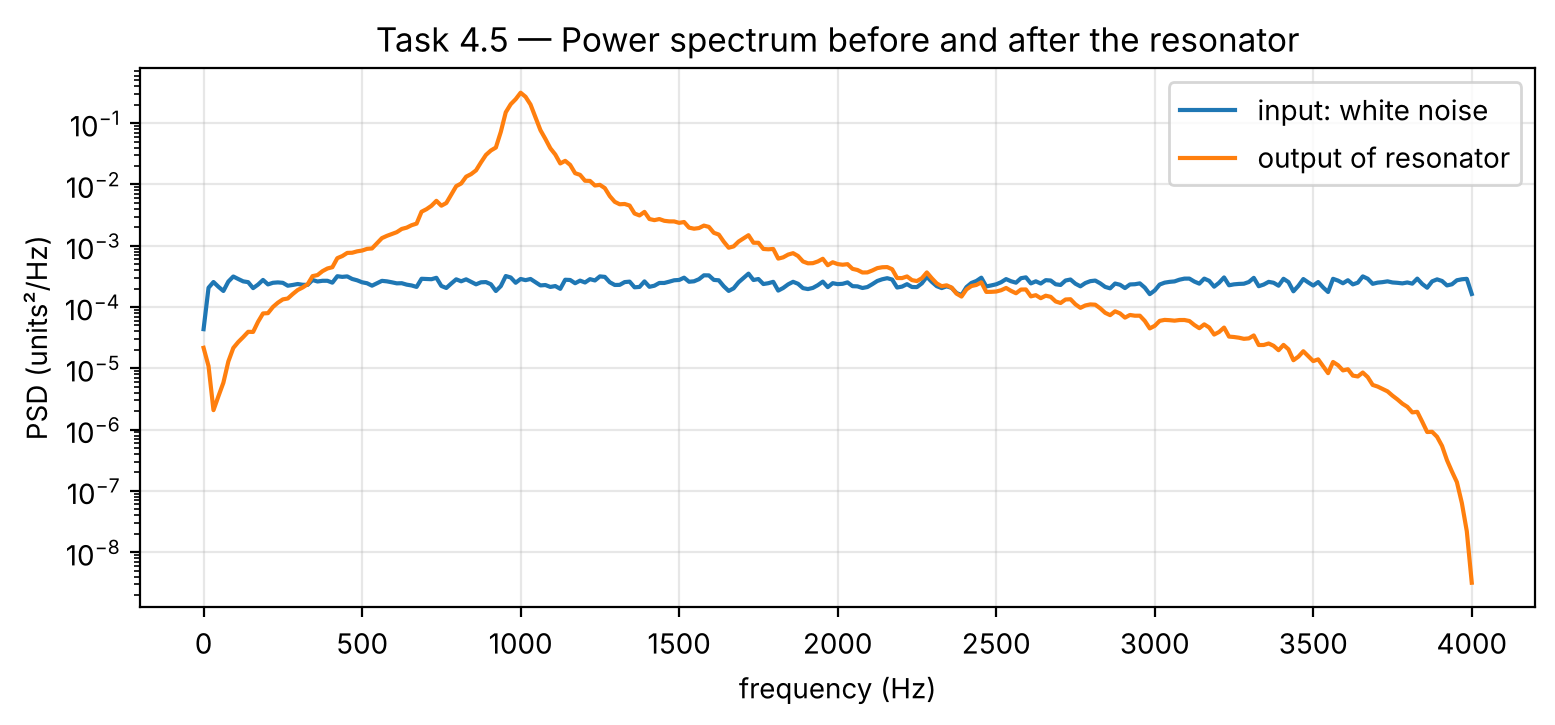

White noise (input):


Resonator output:


In [9]:
rng = np.random.default_rng(4)
noise = rng.standard_normal(2*fs)                         # 2 s of white noise
y = signal.lfilter(b, a, noise)
fw, Pn = signal.welch(noise, fs, nperseg=512)
fw, Py = signal.welch(y, fs, nperseg=512)
plt.semilogy(fw, Pn, label="input: white noise")
plt.semilogy(fw, Py, label="output of resonator")
plt.xlabel("frequency (Hz)"); plt.ylabel("PSD (units²/Hz)"); plt.legend(); plt.grid(alpha=0.3)
plt.title("Task 4.5 — Power spectrum before and after the resonator"); plt.show()
print("White noise (input):"); display(Audio(noise, rate=fs))
print("Resonator output:");   display(Audio(y, rate=fs))

**Result.** The response peaks at 1 kHz with a narrow −3 dB bandwidth of about 76 Hz (equal to the estimate $2(1-r)f_s/2\pi$), and it is zero at 0 Hz and 4 kHz
(the zeros at $z = \pm1$). The flat white noise comes out as a spectrum concentrated around 1 kHz. When played,
the hiss turns into a "whistling" noisy tone at about 1 kHz, like blowing across a bottle.

## Octave cross-check (optional)
`week04_octave_check.m` repeats Tasks 4.1, 4.2 and 4.4 with Octave's `zplane`, `residuez` and `freqz`.

Task 4.1 poles: [0.5 0.25]
Task 4.1 zeros: -1
Task 4.2 residuez(1, a):  r = [-1 2]   p = [0.25 0.5]
Task 4.2 residuez(b, a):  r = [-5 6]   p = [0.25 0.5]
Task 4.4 H1: max |pole| = 0.9434
Task 4.4 H2: max |pole| = 2.0000
Task 4.4 H3: max |pole| = 1.0000
Task 4.4 H4: max |pole| = 0.0000
Saved week04_octave_zplane.png


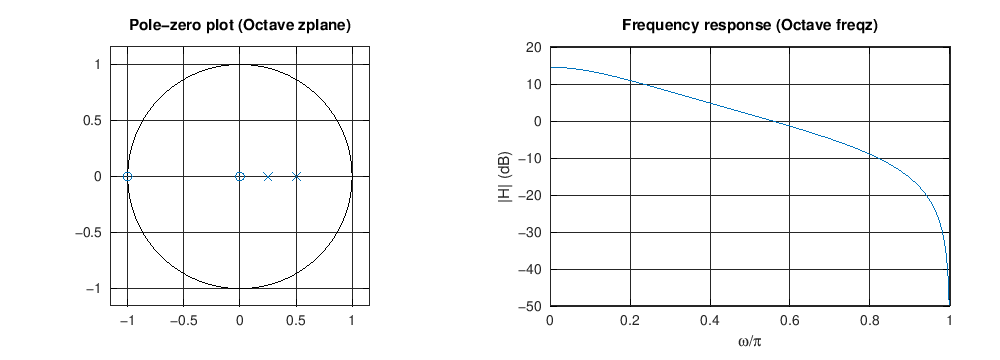

In [10]:
import shutil, subprocess
from IPython.display import Image
if shutil.which("octave"):
    out = subprocess.run(["octave", "--no-gui", "-q", "week04_octave_check.m"],
                         capture_output=True, text=True)
    print(out.stdout.strip())
    display(Image("week04_octave_zplane.png"))
else:
    print("Octave is not installed on this computer - run week04_octave_check.m in Octave instead.")

Octave gives the same poles, residues (2, −1 and 6, −5) and stability results as SciPy. (Octave may list the
poles in a different order, so the residues appear in a different order too. Octave's `zplane` also shows a zero at
$z = 0$: written in powers of $z$, $H(z) = z(z+1)/(z^2 - 0.75z + 0.125)$. SciPy's `tf2zpk` leaves out
these zeros/poles at the origin, which do not change $|H|$.)

## Analysis questions
**1. Explain the effect of $r$ on the bandwidth of the resonance in Task 4.3.**
The closer the poles are to the unit circle, the narrower the resonance. For $r$ near 1 the −3 dB bandwidth is
approximately $\Delta\omega \approx 2(1-r)$ rad/sample. Moving from $r$ = 0.8 to 0.95 makes the peak about 4–5 times
narrower. This is the same effect seen in time: a narrow peak in frequency corresponds to a long ringing
$h(n)$, because the decay $r^n$ is slow. The bandwidths are measured below.

In [11]:
print(f"{'r':>5} {'measured BW (rad)':>18} {'2(1-r)':>8}")
for r in [0.5, 0.8, 0.9, 0.95, 0.97, 0.99]:
    a = [1, -2*r*np.cos(np.pi/4), r**2]
    w, H = signal.freqz([1], a, worN=200000)
    mag = np.abs(H); band = w[mag >= mag.max()/np.sqrt(2)]
    print(f"{r:5.2f} {band[-1]-band[0]:18.4f} {2*(1-r):8.4f}")

    r  measured BW (rad)   2(1-r)
 0.50             1.2094   1.0000
 0.80             0.4828   0.4000
 0.90             0.2139   0.2000
 0.95             0.1029   0.1000
 0.97             0.0610   0.0600
 0.99             0.0201   0.0200


(For r = 0.5 the peak is so broad that the −3 dB band is wide and the approximation does not hold. The formula
becomes accurate as $r \to 1$.)

**2. What happens to $h(n)$ when a pole lies exactly on the unit circle?**
$|p|^n = 1$, so $h(n)$ neither decays nor grows. It keeps oscillating forever with constant amplitude (a sinusoid
at the pole angle, or a constant/alternating sequence for a pole at $z = 1$ or $z = -1$, as in $H_3$). $h(n)$ is
bounded but not absolutely summable, so the system is **marginally stable, not BIBO-stable**. An input at the
same frequency would make the output grow without limit (resonance). A double pole on the circle would make
$h(n)$ grow linearly ($n\,p^n$).

**3. Why does placing zeros at $z = \pm1$ make the resonator a band-pass filter?**
$z = 1$ corresponds to $\omega = 0$ (DC) and $z = -1$ corresponds to $\omega = \pi$ ($f_s/2$ = 4 kHz). A zero on the
unit circle makes $|H| = 0$ at that frequency, because $B(z) = 1 - z^{-2}$ gives $B(1) = B(-1) = 0$. Without the
zeros, a resonator with $B = 1$ still passes some DC and high frequencies. With them, both ends of the band are
forced to zero, and the only region with large gain is around the pole angle (1 kHz). The response passes a
band and rejects both lower and higher frequencies, which is the definition of a band-pass filter.

**4. Use the stability triangle (handout Example 2.4) to check Task 4.4 (a)–(c).**
For $A(z) = 1 + a_1z^{-1} + a_2z^{-2}$ both poles are inside the unit circle if and only if $|a_2| < 1$ and
$|a_1| < 1 + a_2$.

system     a1     a2   |a2|<1        |a1|<1+a2  stable
H1       -1.6   0.89     True 1.6 < 1.89: True    True
H2       -2.5      1    False   2.5 < 2: False   False
H3        0.5   -0.5     True 0.5 < 0.5: False   False


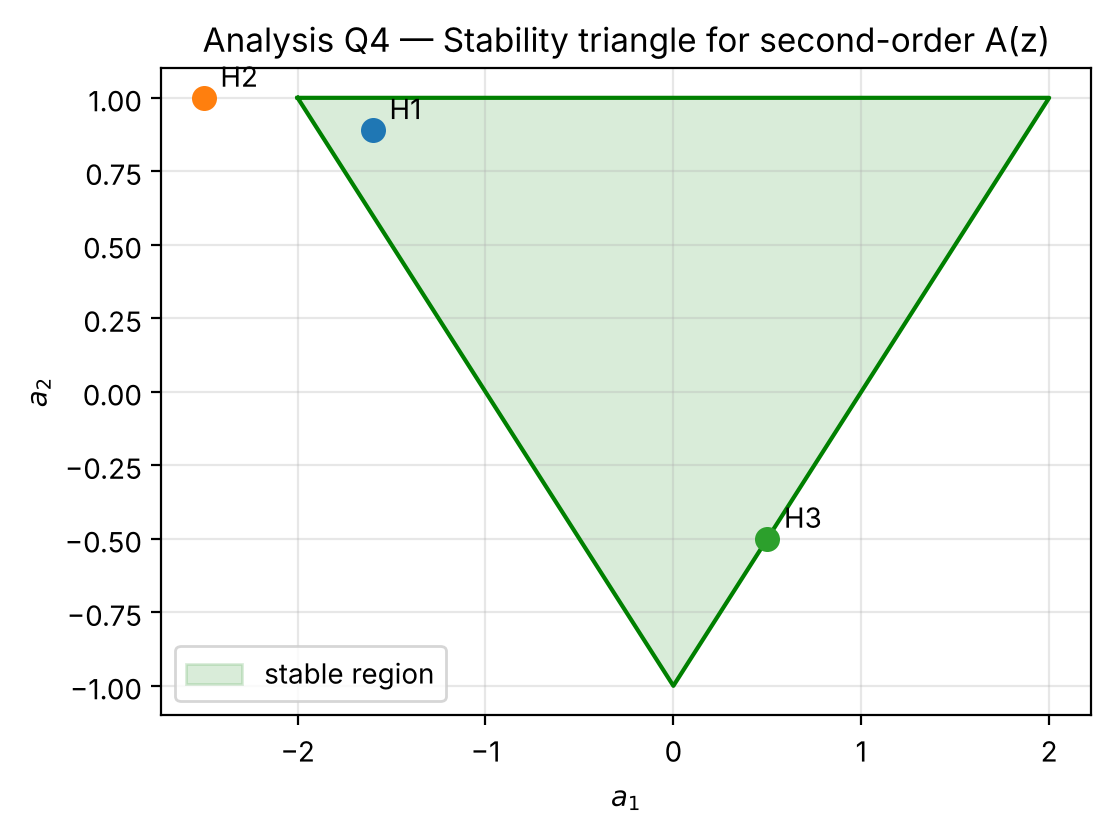

In [12]:
def triangle(a1, a2):
    c1, c2 = abs(a2) < 1, abs(a1) < 1 + a2
    return c1, c2, c1 and c2

print(f"{'system':6} {'a1':>6} {'a2':>6} {'|a2|<1':>8} {'|a1|<1+a2':>16} {'stable':>7}")
for name, a1, a2 in [("H1", -1.6, 0.89), ("H2", -2.5, 1.0), ("H3", 0.5, -0.5)]:
    c1, c2, ok = triangle(a1, a2)
    print(f"{name:6} {a1:6g} {a2:6g} {str(c1):>8} {f'{abs(a1):g} < {1+a2:g}: {c2}':>16} {str(ok):>7}")

fig, ax = plt.subplots(figsize=(6, 4.2))
ax.fill([-2, 2, 0], [1, 1, -1], color="green", alpha=0.15, label="stable region")
ax.plot([-2, 2, 0, -2], [1, 1, -1, 1], "g-")
for name, a1, a2 in [("H1", -1.6, 0.89), ("H2", -2.5, 1.0), ("H3", 0.5, -0.5)]:
    ax.plot(a1, a2, "o", ms=8); ax.annotate(name, (a1, a2), xytext=(6, 4), textcoords="offset points")
ax.set_xlabel("$a_1$"); ax.set_ylabel("$a_2$"); ax.grid(alpha=0.3); ax.legend(loc="lower left")
ax.set_title("Analysis Q4 — Stability triangle for second-order A(z)"); plt.show()

- **(a) $H_1$:** $a_1 = -1.6$, $a_2 = 0.89$. $|0.89| < 1$ and $1.6 < 1.89$, so the point is inside the triangle: **stable** ✔
- **(b) $H_2$:** $a_1 = -2.5$, $a_2 = 1$. $|a_2| = 1$ is not $< 1$, and $2.5 > 2$, so the point is outside: **unstable** ✔
- **(c) $H_3$:** $a_1 = 0.5$, $a_2 = -0.5$. $|a_2| < 1$, but $|a_1| = 0.5$ is not $< 1 + a_2 = 0.5$. The point lies
  exactly **on the edge** of the triangle, which means a pole on the unit circle ($z = -1$): **not stable** (marginal) ✔

The triangle agrees with the pole positions found in Task 4.4.

## Deliverables
`COU07506_Week04_250242423358.ipynb` with Tasks 4.1–4.5, the plots, the answers and the AI-use statement.
The mini-project proposal draft is ready for discussion with Group 30.

## AI-use statement
**Tool used:** Claude (Anthropic), a generative-AI assistant.

**What it was used for:** suggesting and explaining code for the tasks in this notebook and drafting
explanations, which I then reviewed and rewrote in my own words.

**How the results were checked:** residuez results were compared with my hand partial fractions (2, −1) and with lfilter and the closed form; pole positions were cross-checked in Octave with roots/zplane; stability verdicts were confirmed both from |pole| and from whether h(n) decays, and again with the stability triangle; the resonator peak frequency was measured (1 kHz target).

I have run the notebook from top to bottom (Restart kernel → Run all) and I can explain every line of the code.